In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

%matplotlib inline 
pd.set_option('display.max_columns', None)

In [ ]:
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')



In [10]:
df

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers
...,...,...,...,...,...,...,...,...,...
2443646,2828589,B0CHSD7P2Q,"Motorbike Armour, Motorbike Clothing, Cycling ...",0.0,0,22.34,False,0,Motorbike Clothing
2443647,2828590,B0B7B8FNBQ,PROFIRST Waterproof Motorcycle 2 Piece Ladies ...,0.0,0,97.99,False,0,Motorbike Clothing
2443648,2828591,B0BD5FL5FB,Men’s Motorcycle Motorbike Biker Trousers Kevl...,0.0,0,52.99,False,0,Motorbike Clothing
2443649,2828592,B008OYLL4I,Texpeed Mens Motorcycle Motorbike Biker Trouse...,4.3,404,79.99,False,0,Motorbike Clothing


### 1. Crosstab Analysis

In [13]:
crosstab_result = pd.crosstab(df['category'], df['isBestSeller'])
crosstab_result


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [ ]:
proportions = df.groupby('category')['isBestSeller'].mean()
sorted_proportions = proportions.sort_values(ascending=False)
sorted_proportions.head(10)


category
Grocery                           0.058135
Smart Home Security & Lighting    0.057692
Health & Personal Care            0.057686
Mobile Phone Accessories          0.042471
Power & Hand Tools                0.035339
Billiard, Snooker & Pool          0.032129
Pet Supplies                      0.030200
Home Brewing & Wine Making        0.028455
Wind Instruments                  0.028000
Mirrors                           0.028000
Name: isBestSeller, dtype: float64

### 2. Statistical Tests:

In [22]:
from scipy.stats import chi2_contingency
chi2_stats, chi2_pvalue, _, _ = chi2_contingency(crosstab_result)
float(chi2_pvalue)

0.0

In [23]:
float(chi2_pvalue) < 0.05

True

We have a significant association between the values.

In [25]:
from scipy.stats.contingency import association
association(crosstab_result, method='cramer')

0.1222829439760564

The strength of the association is weak between the values.

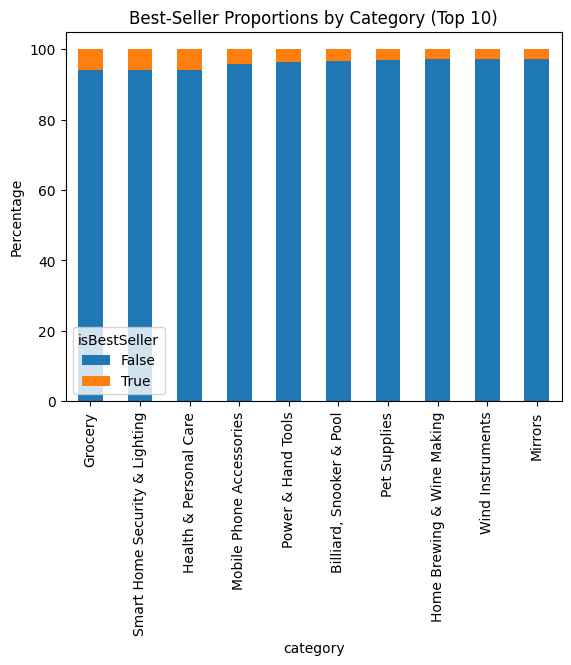

In [32]:
crosstab_pct = crosstab_result.div(crosstab_result.sum(axis=1), axis=0) * 100
top10 = crosstab_pct.sort_values(by=True, ascending=False).head(10)

top10.plot(kind='bar', stacked=True)
plt.ylabel('Percentage')
plt.title('Best-Seller Proportions by Category (Top 10)')
plt.show()